# Building an optimal portfolio system

1) Forecast (currently vry simple OLS)
2) Risk model (factor model)
3) Cost model (currently with only spread)
4) Optimization framework (with scaling and factor sparsity for numerical stability)

### Issues:
- Universe selected from 2023-2025, but not splitting or rolling forecasts right now: **lookahead in forecasts**

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [s for s in [line.strip() for line in f] if s not in ['CRCL', 'OMDA']]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)).alias("spread_return"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid", "spread_return"]).last()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,40,00), pl.time(15,49,59)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
             / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
    )
)
test_data = data.filter(pl.col("date").is_between(pl.date(2026,2,1), pl.date(2026,6,11), closed="left"))
test_data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64
2026-02-02,"""AAPL""","""A""",4777020,269.86,269.885,0.000037,270.01,3.2271e9,0.00234,2.3978e8,1.2891e9,-1,-2.3978e8,-0.186001,0.000463,0.000176,0.00259,-0.27027,-0.0007
2026-02-02,"""ABNB""","""B""",337164,131.4,131.4,0.000152,131.31,1.0106e8,-0.000228,656211.6,4.4303e7,1,656211.6,0.014812,-0.000685,-0.000973,0.000022,0.513514,0.000011
2026-02-02,"""ADBE""","""B""",239440,292.72,292.705,0.000307,293.38,3.3585e8,0.00065,2.7188e6,7.0089e7,1,2.7188e6,0.038791,0.002306,0.002018,0.0009,0.567568,0.000511
2026-02-02,"""ADI""","""B""",466700,315.72,315.62,0.00057,316.86,2.1504e8,-0.003662,3.0344e7,1.47346524e8,1,3.0344e7,0.20594,0.003929,0.003641,-0.003411,0.864865,-0.00295
2026-02-02,"""ADP""","""N""",148423,248.31,248.33,0.000322,247.56,1.3475e8,0.000846,0.0,3.6855e7,0,0.0,0.0,-0.003101,-0.003388,0.001097,0.418919,0.000459
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""TTD""","""A""",316065,19.34,19.35,0.001034,19.29,7.2089e7,-0.001033,5.3613e6,6112697.1,-1,-5.3613e6,-0.87707,-0.003101,-0.000963,0.000682,-0.945946,-0.000646
2026-06-10,"""TXN""","""A""",937022,282.53,282.645,0.000743,282.01,4.8747e8,-0.003877,3.1504e7,2.6474e8,-1,-3.1504e7,-0.119,-0.002247,-0.000108,-0.002161,-0.405405,0.000876
2026-06-10,"""UAL""","""B""",459492,102.84,102.855,0.000292,102.78,1.0664e8,-0.000097,2.9506e6,4.7254e7,1,2.9506e6,0.062441,-0.000729,0.001409,0.001618,0.432432,0.0007


## Daily MVO Optimizer

In [4]:
import cvxpy as cp
import scipy

class ForecastModel:
    def __init__(self, universe, model, features):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.model = model
        self.features = features

    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        alpha = np.zeros(len(self.universe))
        preds = self.model.predict(day_df[self.features].to_numpy()).ravel()  # scaled inside pipeline
        for symbol, p in zip(day_df["symbol"], preds):
            alpha[self.sym_idx_map[symbol]] = p
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame, commission: float) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread, comm_rate in zip(day_df["symbol"], day_df["spread_return"], commission / day_df['entry_price']):
            cost[self.sym_idx_map[symbol]] = (spread * 0.5) + (2 * comm_rate)
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        self.scale = None
        
    def set_problem(self, Sigma_r, Sigma_f, Loadings, eps_diag, lam, vol_cap, scale = None):
        self.x     = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        self.Sigma_r = cp.Constant(Sigma_r)
        self.L = cp.Constant(Loadings)
        self.eps_diag = eps_diag
        self.scale = float(vol_cap if scale is None else scale)
        self.D = np.diag(eps_diag)
        
        self.objective = cp.Maximize(
            self.alpha @ self.x
            # - (lam * self.scale / 2) * cp.quad_form(self.x, Sigma_r)
            - (lam * self.scale / 2) * ( cp.quad_form(self.L @ self.x, Sigma_f) + cp.quad_form(self.x, self.D) )
            - (self.cost / 2) @ cp.abs(self.x)
        )

        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt  = np.sqrt(self.eps_diag)
        quad_risk = cp.norm(cp.hstack([Sigma_f_sqrt @ self.L @ self.x, cp.multiply(D_sqrt, self.x)]), 2)   # = √(xᵀΣx) but sparse with factors
        self.constraints = [
            self.x @ Loadings[0,:] == 0,                 # market neutrality
            cp.sum(self.x) == 0,                         # dollar neutrality
            quad_risk <= vol_cap / self.scale,           # √(xᵀΣx) ≤ target daily dollar volatility, with scale factor
        ]
        
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.problem.solve(solver=cp.SCS, warm_start=True)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return self.x.value * self.scale                # optimal dollar portfolio

## Parallel daily solve

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

### Loading Forecast and Risk Models

In [5]:
import joblib

# Load the model back into memory
loaded_model = joblib.load("../forecast/ridge_pipe.joblib")
features = ["norm_rank_net_imb", "recent_return", "norm_rank_net_x_recent_xm"]

L = np.load("../covariance/loadings.npy")
F = np.load("../covariance/factor_returns.npy")
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_vec.npy")
SIGMA_F = np.load("../covariance/factor_cov_matrix.npy")
SIGMA_R = np.load("../covariance/cov_matrix.npy")

f_model = ForecastModel(ACTIVE_SET, model=loaded_model, features=features)
c_model = CostModel(ACTIVE_SET)

In [6]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed
import warnings


N_JOBS = max(1, os.cpu_count() - 2)
COMMISSION_PER_SHARE = 0.0035
LAMBDA = 1e-9                                  # Risk aversion per dollar, ~OOM of 1 / (capital * 1e-3).
DAILY_DOLLAR_VOL_CAP = 0.0063 * 1e9            # 0.0063 * 1/lambda amount=> annual vol 10%. Real dollar pnl is sigma-bar (0.02) * cap.

def _solve_chunk(symbols, Sigma_r, Sigma_f, Loadings, eps_diag, lam, vol_cap, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    warnings.filterwarnings("ignore", message="Solution may be inaccurate")
    opt = Optimizer(symbols)
    opt.set_problem(Sigma_r=Sigma_r, Sigma_f=Sigma_f, Loadings=Loadings, eps_diag=eps_diag, lam=lam, vol_cap=vol_cap)        # compile paid once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = test_data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day, COMMISSION_PER_SHARE))
    for d in all_dates
    for day in [data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, DAILY_DOLLAR_VOL_CAP, chunk) for chunk in chunks
)

weights = {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

solved 90 days across 12 workers


### Plotting / Accounting

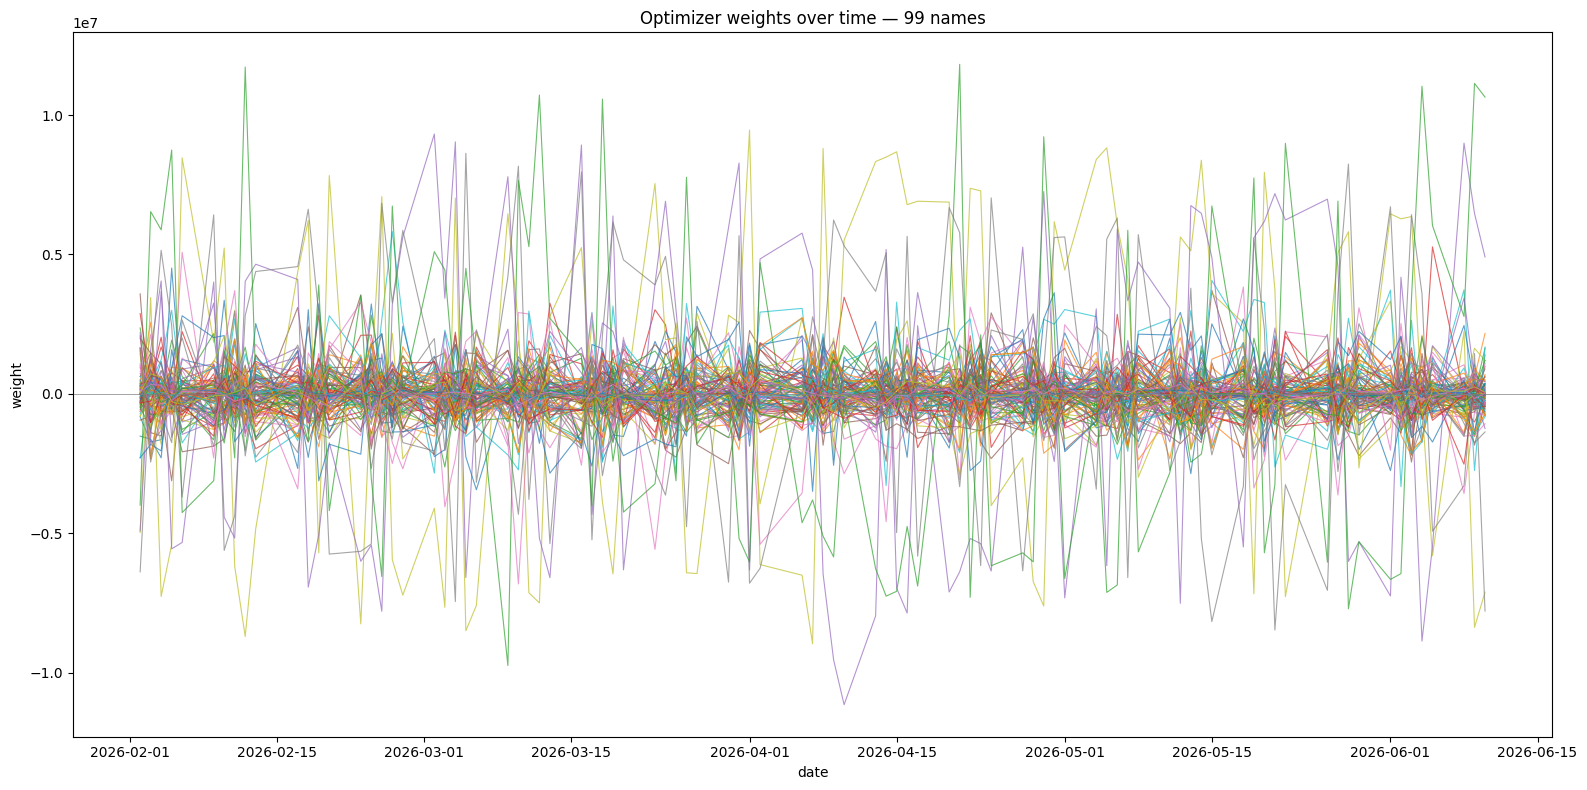

In [7]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

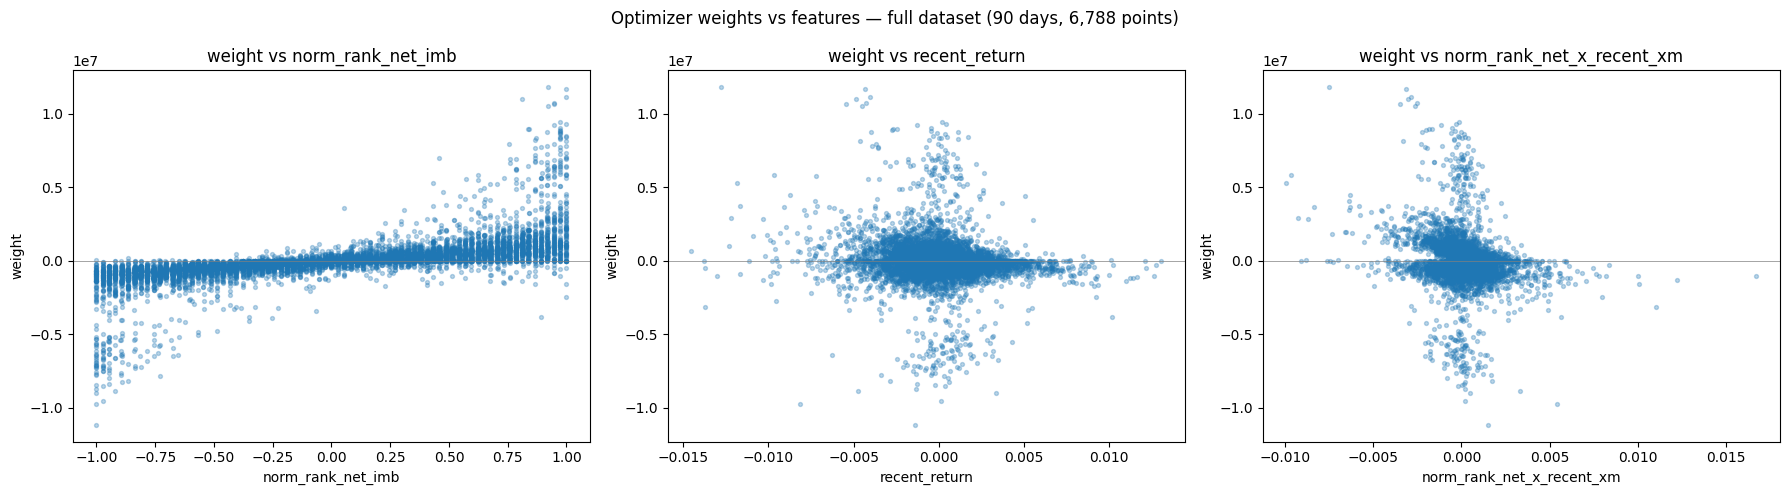

In [8]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

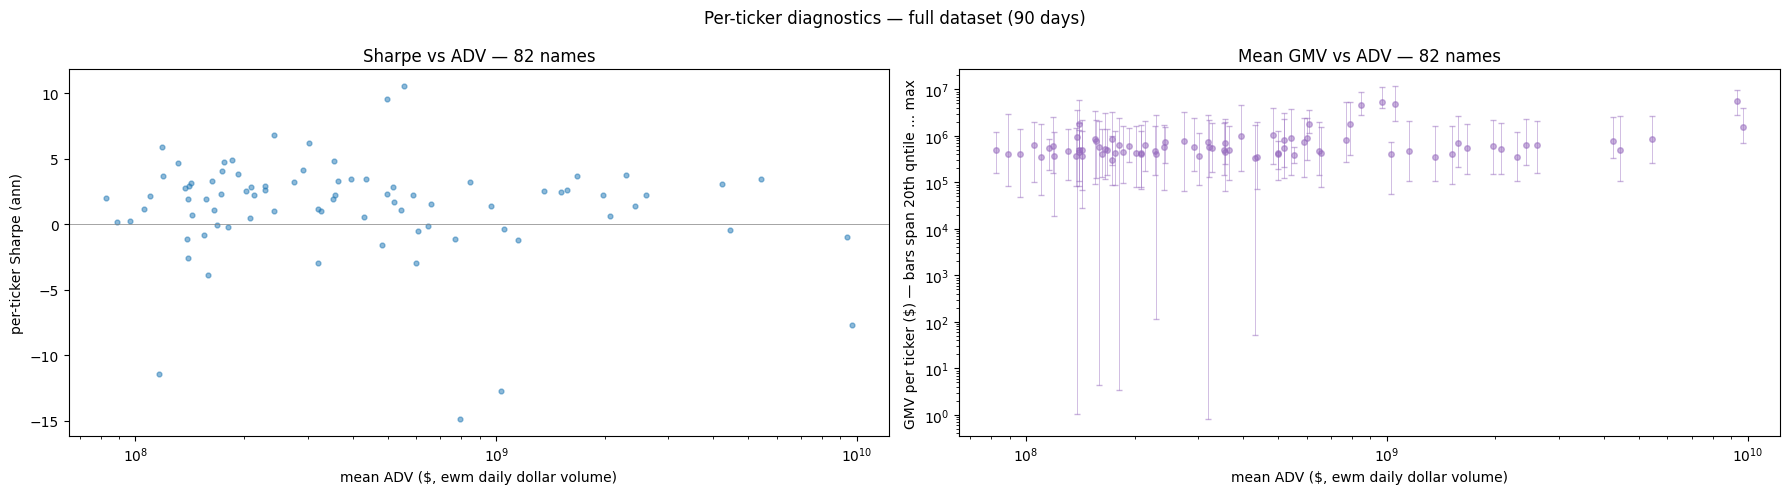

In [9]:
# Per-ticker scatters over the FULL dataset: Sharpe vs ADV, and mean GMV vs ADV.
# Rebuilds per-name daily net PnL with the SAME cost model as the PnL cell below,
# then collapses to one point per ticker:
#   - Sharpe_i  = mean_t(net_pnl_i,t) / std_t(net_pnl_i,t) * sqrt(252)   (zero-position days included)
#   - GMV_i,t   = |$pos_i,t|  -> mean per ticker, with bars spanning its min..max
#   - ADV_i     = mean of the day's ewm daily dollar volume for that name
ANN = 252

pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

name_daily = (
    data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate")
    )
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")
         - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
        pl.col("dollar_pos").abs().alias("gmv_name"),
    )
)

per_name = (
    name_daily
    .group_by("symbol")
    .agg(
        (pl.col("net_pnl_name").mean() / pl.col("net_pnl_name").std(ddof=1) * np.sqrt(ANN)).alias("sharpe"),
        pl.col("ADV").mean().alias("adv_mean"),
        pl.col("gmv_name").mean().alias("gmv_mean"),
        pl.col("gmv_name").quantile(0.2).alias("gmv_min"),
        pl.col("gmv_name").max().alias("gmv_max"),
        pl.len().alias("n_days"),
    )
    .filter((pl.col("n_days") > 1) & pl.col("sharpe").is_finite())
    .sort("adv_mean")
)

adv      = per_name["adv_mean"].to_numpy()
sharpe_n = per_name["sharpe"].to_numpy()
gmv_mean = per_name["gmv_mean"].to_numpy()
gmv_lo   = gmv_mean - per_name["gmv_min"].to_numpy()   # bar down to min (>= 0)
gmv_hi   = per_name["gmv_max"].to_numpy() - gmv_mean   # bar up to max   (>= 0)

fig, (axS, axG) = plt.subplots(1, 2, figsize=(18, 5))

axS.scatter(adv, sharpe_n, alpha=0.5, s=12)
axS.axhline(0, color="grey", lw=0.5)
axS.set_xscale("log")
axS.set_xlabel("mean ADV ($, ewm daily dollar volume)")
axS.set_ylabel("per-ticker Sharpe (ann)")
axS.set_title(f"Sharpe vs ADV — {len(per_name)} names")

axG.errorbar(adv, gmv_mean, yerr=[gmv_lo, gmv_hi], fmt="o", ms=4, alpha=0.5,
             elinewidth=0.6, capsize=2, color="tab:purple")
axG.set_xscale("log")
axG.set_yscale("log")
axG.set_xlabel("mean ADV ($, ewm daily dollar volume)")
axG.set_ylabel("GMV per ticker ($) — bars span 20th qntile ... max")
axG.set_title(f"Mean GMV vs ADV — {len(per_name)} names")

fig.suptitle(f"Per-ticker diagnostics — full dataset ({len(weights)} days)")
fig.tight_layout()
plt.show()

In [10]:
per_name.bottom_k(10, by="sharpe")

symbol,sharpe,adv_mean,gmv_mean,gmv_min,gmv_max,n_days
cat,f64,f64,f64,f64,f64,u64
"""SOXL""",-14.911384,7.9289e8,1.8204e6,381065.23951,5.3926e6,4
"""GLD""",-12.756526,1.0296e9,402691.123849,57043.301465,748338.946234,2
"""UBER""",-11.430667,1.1592e8,553544.494444,188058.826857,836244.827849,3
"""SPY""",-7.690453,9.6974e9,1.5301e6,706766.176959,3.9428e6,10
"""MPWR""",-3.902091,1.5889e8,573595.273727,4.413276,2.0541e6,90
"""SHOP""",-2.947574,3.2072e8,574892.988391,131736.911397,2.1606e6,90
"""ASML""",-2.936112,5.9996e8,894149.192639,304587.329233,2.3659e6,90
"""NVDL""",-2.604473,1.3991e8,1.8414e6,546367.529221,5.8211e6,90
"""LRCX""",-1.594369,4.8297e8,1.0416e6,248752.464605,4.0489e6,90


Days traded:        90
[Avg, Std] GMV:     $63,526,459 $3,559,438
Gross PnL:          $2,575,807
Total cost:         $1,009,653
Total net PnL:      $1,566,155
Sharpe (ann):       5.20
Daily hit rate:     73.3%


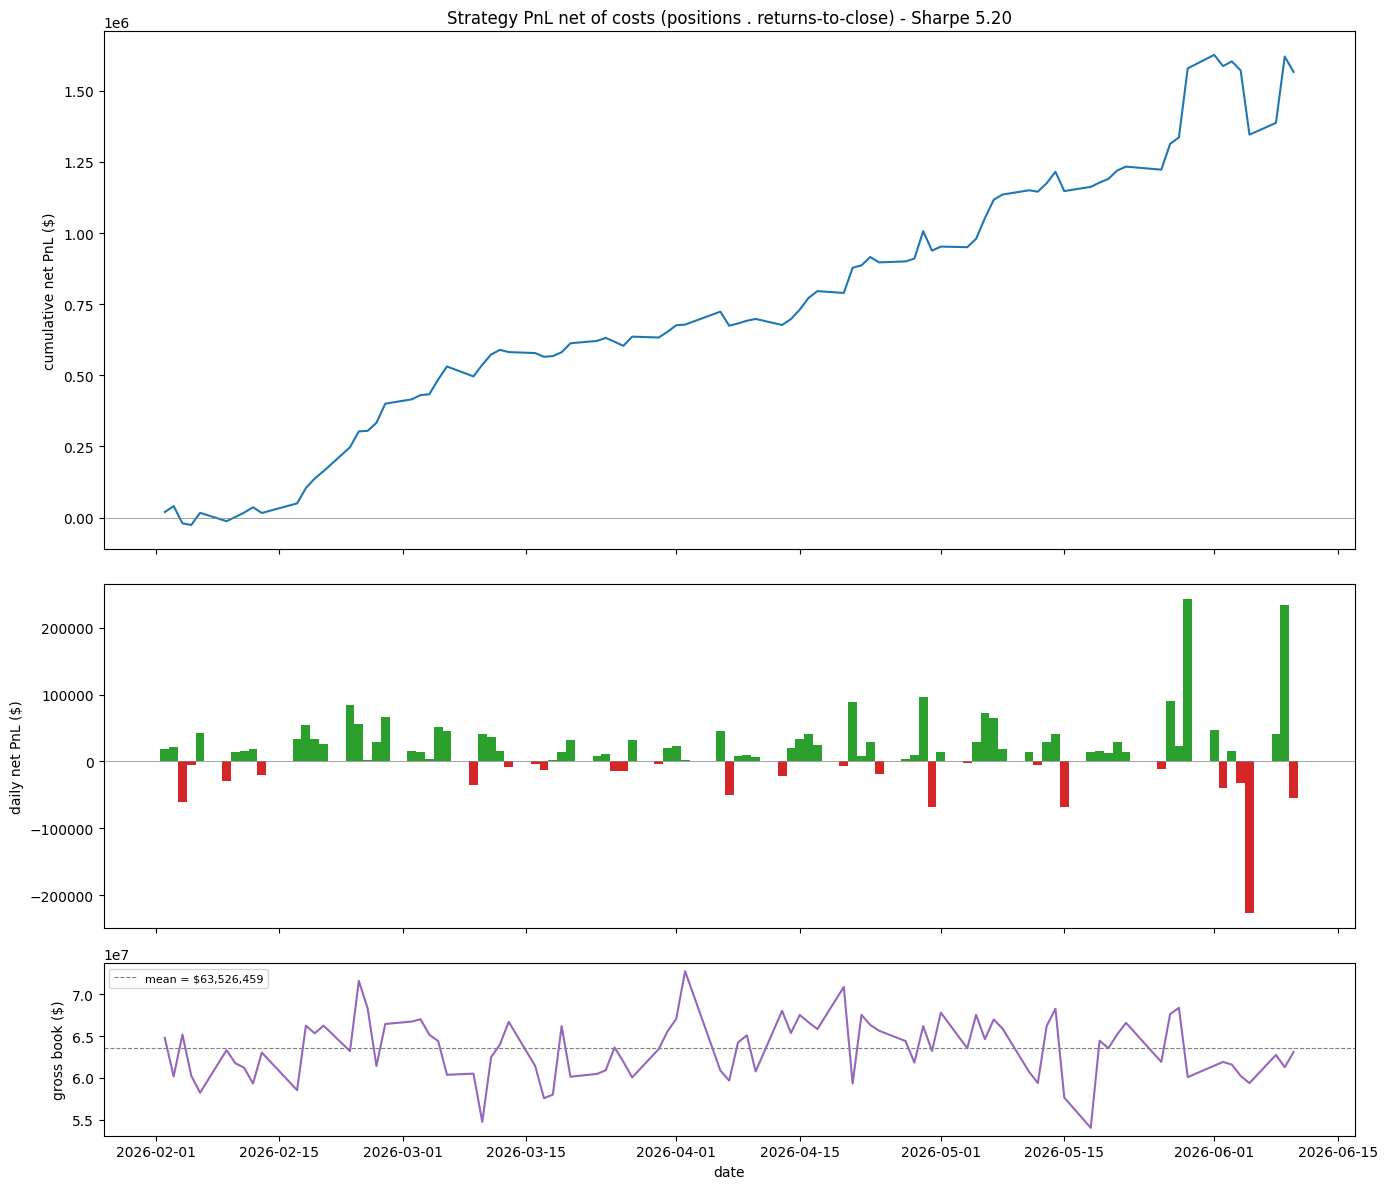

date,net_pnl,gross_pnl,cost,GMV,cum_pnl
date,f64,f64,f64,f64,f64
2026-02-02,19356.869259,31405.88529,12049.01603,6.4780e7,19356.869259
2026-02-03,21019.5764,36183.708478,15164.132078,6.0169e7,40376.445659
2026-02-04,-60794.03666,-46044.168639,14749.868021,6.5185e7,-20417.591
2026-02-05,-5711.179742,7154.282296,12865.462038,6.0249e7,-26128.770742
2026-02-06,42786.818178,51312.375504,8525.557327,5.8216e7,16658.047436
…,…,…,…,…,…
2026-06-04,-31598.258366,-18259.318449,13338.939918,6.0227e7,1.5714e6
2026-06-05,-225741.226134,-216590.515597,9150.710537,5.9372e7,1.3457e6
2026-06-08,41273.021108,54780.884502,13507.863395,6.2740e7,1.3869e6


In [11]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (return from entry to the closing auction_i).
# Costs charged as a dot product  |$pos| . cost_rate:
#   - spread:     HALF the quoted spread, ENTRY only (the auction exit has no spread).
#   - commission: $0.0035/share on BOTH legs; spread_return already bundles 0.0035/price (one leg).
ANN = 252


# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"),                        # per-leg commission, as a return
    )
    # spread_return is the pure quoted spread (ask-bid)/mid. Charge half the spread (cross ONCE
    # on entry; the auction exit has no spread) + commission on BOTH legs.
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate"),
    )
    .with_columns(
        (pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("cost"),                         # dot product: |$pos| . cost_rate
        (pl.col("gross_pnl") - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("cost").sum().alias("cost"),
        pl.col("dollar_pos").abs().sum().alias("GMV"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum_pnl  = pnl_daily["cum_pnl"].to_numpy()
mean_gmv = pnl_daily["GMV"].mean()                  # FIXED capital base = avg gross book
std_gmv = pnl_daily["GMV"].std() 

sharpe  = pnl.mean() / pnl.std(ddof=1) * np.sqrt(ANN)
ann_ret = pnl.mean() * ANN

print(f"Days traded:        {len(pnl)}")
print(f"[Avg, Std] GMV:     ${mean_gmv:,.0f} ${std_gmv:,.0f}")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total cost:         ${pnl_daily['cost'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gmv = pnl_daily["GMV"].to_numpy()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, height_ratios=[3, 2, 1])

ax1.plot(dts, cum_pnl, color="tab:blue")
ax1.axhline(0, color="grey", lw=0.5)
ax1.set_ylabel("cumulative net PnL ($)")
ax1.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}")

ax2.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax2.axhline(0, color="grey", lw=0.5)
ax2.set_ylabel("daily net PnL ($)")

ax3.plot(dts, gmv, color="tab:purple")
ax3.axhline(mean_gmv, color="grey", lw=0.8, ls="--", label=f"mean = ${mean_gmv:,.0f}")
ax3.set_ylabel("gross book ($)")
ax3.set_xlabel("date")
ax3.legend(loc="upper left", fontsize=8)

fig.tight_layout()
plt.show()

pnl_daily

#### Some diagnostics

In [12]:
ANN = 252
ret = (pnl_daily["net_pnl"] / pnl_daily["GMV"]).to_numpy()   # daily return on gross book
ir  = ret.mean() / ret.std(ddof=1) * np.sqrt(ANN)
print(f"Ex-Post (Realized) Information ratio (ann): {ir:.2f}")

Ex-Post (Realized) Information ratio (ann): 4.96


In [13]:
ANN = 252
alpha_by_day = {d: a for d, a, _ in day_records}      # dense alpha, ACTIVE_SET order
cost_by_day = {d: c for d, _, c in day_records}

exante = []
for d in sorted(weights):
    x = np.array([weights[d][s] for s in ACTIVE_SET])            # $ positions, same order
    a = alpha_by_day[d]                                          # expected returns
    exp_pnl = a @ x - cost_by_day[d] @ np.abs(x)                 # net expected daily $ PnL
    exp_var = (L @ x) @ SIGMA_F @ (L @ x) + np.sum(EPS_DIAG * x**2)   # matches optimizer's risk term
    exante.append(exp_pnl / np.sqrt(exp_var) if exp_var > 0 else np.nan)

exante = np.array(exante)
print(f"Ex-ante (Expected) IR (ann):     {np.nanmean(exante) * np.sqrt(ANN):.2f}")
print(f"Mean expected $vol:   {np.nanmean([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")
print(f"Mean expected $vol:   {np.nanmax([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")

Ex-ante (Expected) IR (ann):     0.12
Mean expected $vol:   6,298,231
Mean expected $vol:   6,300,305


In [14]:
f"{0.0063 * 1e9:,.2f}"

'6,300,000.00'

In [15]:
from scipy.stats import pearsonr, spearmanr
r, pval = pearsonr(pnl_daily["GMV"], pnl_daily["cum_pnl"])
print(f"Pearson Corr of GMV and PnL: {r:,.5f}")

Pearson Corr of GMV and PnL: 0.00550


### Parameter Sweeps

In [16]:
# Two independent 1-D parameter sweeps -> GMV (avg gross book = mean_t sum_i |$pos_{i,t}|).
# Each grid point re-solves EVERY day's QP, reusing the already-built `day_records`,
# `_solve_chunk`, `_split_contiguous` and the loaded covariance pieces from the parallel
# solve above. One parameter varies; the other is held at its baseline (LAMBDA /
# DAILY_DOLLAR_VOL_CAP). Run AFTER the parallel-solve cell (it defines those names).

def _avg_gmv(lam, vol_cap):
    """Solve all days at (lam, vol_cap); return mean daily GMV = mean_t( sum_i |$pos| )."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, vol_cap, chunk)
        for chunk in chunks
    )
    gmv_by_day = [np.abs(ws).sum() for chunk in chunk_results for _, ws in chunk]
    return float(np.mean(gmv_by_day)), float(np.std(gmv_by_day))

# --- Sweep grids ---
lambda_grid = np.linspace(1e-9, 1e-8, 25)            # risk aversion per dollar (~ 1/capital)

gmv_vs_lambda = [_avg_gmv(lam, 0.0063 * (1/lam)) for lam in lambda_grid]

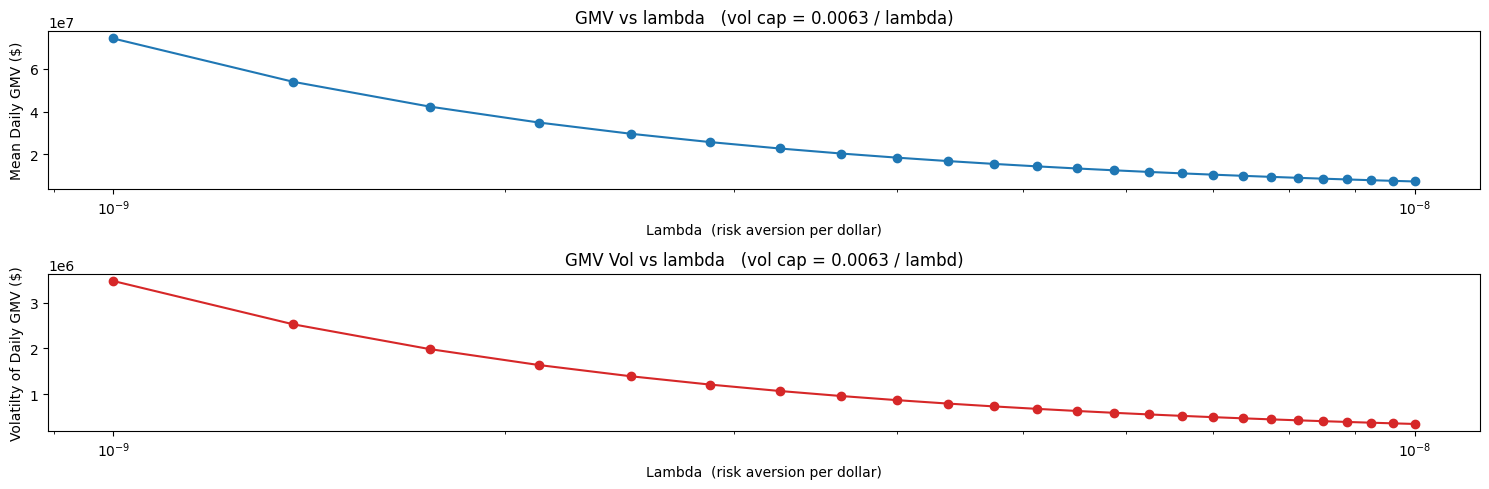

In [17]:
# --- Plots: GMV for each sweep ---
fig, (ax_mean, ax_std) = plt.subplots(2, 1, figsize=(15, 5))

ax_mean.plot(lambda_grid, [mean for (mean, std) in gmv_vs_lambda], marker="o", color="tab:blue")
# ax_mean.plot(lambda_grid, [std for (mean, std) in gmv_vs_lambda], marker="o", color="tab:orange")
ax_mean.set_xlabel("Lambda  (risk aversion per dollar)")
ax_mean.set_ylabel("Mean Daily GMV ($)")
ax_mean.set_title(f"GMV vs lambda   (vol cap = 0.0063 / lambda)")
ax_mean.set_xscale("log")

ax_std.plot(lambda_grid, [std for (mean, std) in gmv_vs_lambda], marker="o", color="tab:red")
ax_std.set_xlabel("Lambda  (risk aversion per dollar)")
ax_std.set_ylabel("Volatilty of Daily GMV ($)")
ax_std.set_title(f"GMV Vol vs lambda   (vol cap = 0.0063 / lambd)")
ax_std.set_xscale("log")


fig.tight_layout()
plt.show()

### Notes
- Risk aversion is generally ~ 1/CAPITAL, within a factor of 2. Then GMV is is abs sum of positions. Each position is then in $ units.
- Assumption to get on wtih life with best-k approx: idiosyncratic covariance/variance error is evenly distributed over assets
        (assuming theres the cov matrix, and then a per asset volatility error on teh diagonal).
        - GARCH(1,1) on the diagonal error epsilon (D) that is time varying and the factor covariance doesn't capture.
- Market neutrality: get loadings and constrain that P dot L is 0.
- Better than PCA is a random matrix theory/eigenvalue clipping work
- Generalized alpha trick: think about operators. Think about a cross-sectionalized operator.
